In [1]:
import tellurium as te
import numpy as np
import matplotlib.pyplot as plt

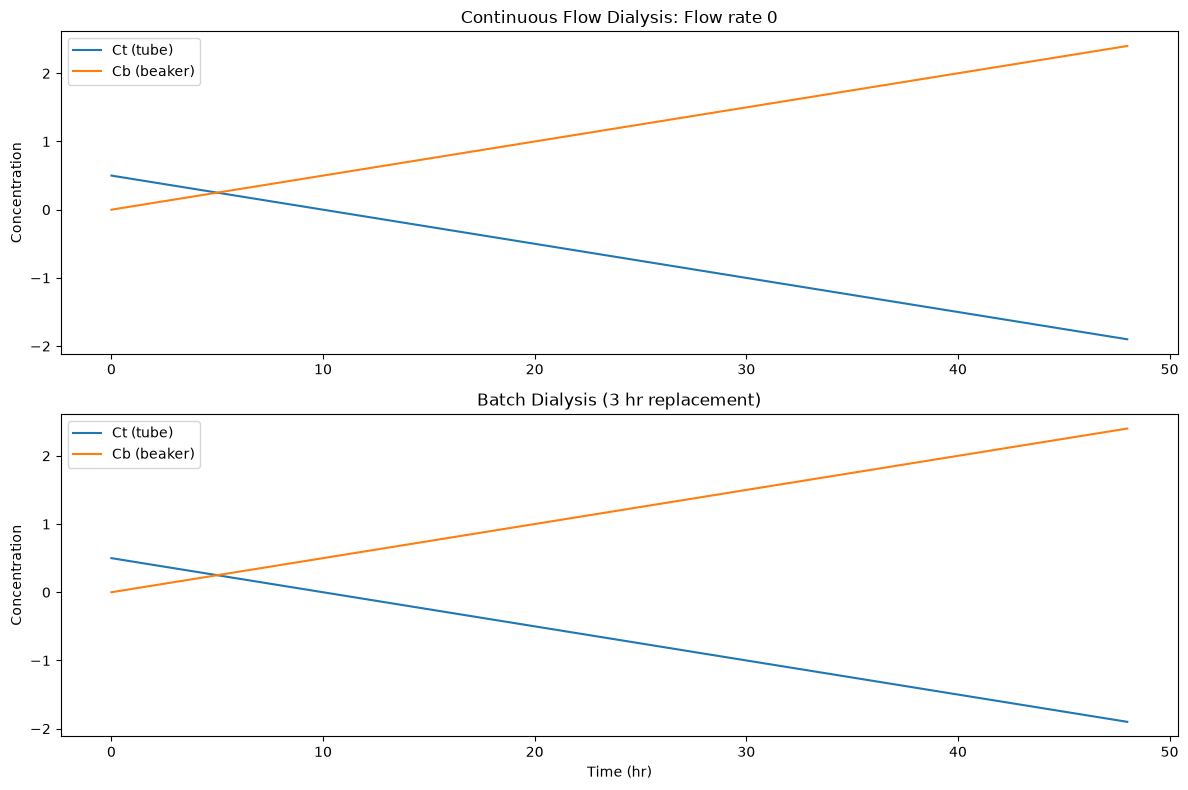

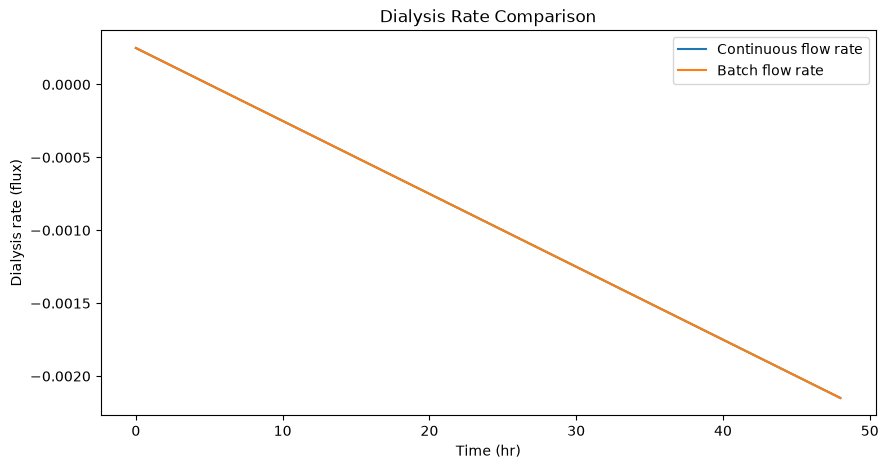

In [30]:

# -----------------------------
# Parameters
# -----------------------------
V_t = 0.005   # tube volume (L) currently 10 tubes
V_b = 0.5      # beaker volume (L)
kA = 0.0005      # mass transfer coefficient (L/hr)
Q = 0        # flow rate (L/hr) for continuous case
change_time = 3

t_end = 48     # total time (hours)

# -----------------------------
# MODEL 1: Continuous Flow
# -----------------------------
model_cont = f"""
model continuous_dialysis

    # Compartments (volume scaling)
    Vt = {V_t}
    Vb = {V_b}

    
    Mt = Vt * 100      # initial Ct = 100
    Mb = 0

    # Species

    Ct = Mt / Vt
    Cb = Mb / Vb

    # Parameters
    kA = {kA}
    Q = {Q}

    # Flux
    J = kA*(max(Ct,0) - Cb)

    # ODEs
    Mt' = -J
    Mb' =  J - (Q)*Cb

end
"""

r_cont = te.loada(model_cont)
r_cont.integrator = 'cvode'
res_cont = r_cont.simulate(0, t_end, 5000)

# -----------------------------
# MODEL 2: Batch Replacement
# -----------------------------
model_batch = f"""
model batch_dialysis

    Vt = {V_t}
    Vb = {V_b}

    
    Mt = Vt * 100      # initial Ct = 100
    Mb = 0

    Ct = Mt / Vt
    Cb = Mb / Vb
    
    next_reset = {change_time}

    kA = {kA}

    J = kA*(max(Ct,0) - Cb)

    Mt' = -J
    Mb' =  J  
    at (time >= next_reset): 
        Cb = 0, next_reset = next_reset + {change_time}


end
"""

r_batch = te.loada(model_batch)

# simulate with periodic reset every 3 hours
times = []
Ct_vals = []
Cb_vals = []
J_vals = []

current_time = 0
dt = 3.0

while current_time < t_end:
    result = r_batch.simulate(current_time, current_time + dt, 5000)

    # store results
    times.extend(result[:, 0])
    Ct_vals.extend(result[:, 1])
    Cb_vals.extend(result[:, 2])

    # compute flux J
    J_vals.extend(kA * (result[:, 1] - result[:, 2]))

    # reset beaker concentration (buffer replacement)


    current_time += dt

# convert to arrays
times = np.array(times)
Ct_vals = np.array(Ct_vals)
Cb_vals = np.array(Cb_vals)
J_vals = np.array(J_vals)

# -----------------------------
# Plot results
# -----------------------------
plt.figure(figsize=(12, 8))

# Continuous case
plt.subplot(2,1,1)
plt.plot(res_cont[:,0], res_cont[:,1], label="Ct (tube)")
plt.plot(res_cont[:,0], res_cont[:,2], label="Cb (beaker)")
plt.title(f"Continuous Flow Dialysis: Flow rate {Q}")
plt.ylabel("Concentration")
plt.legend()

# Batch case
plt.subplot(2,1,2)
plt.plot(times, Ct_vals, label="Ct (tube)")
plt.plot(times, Cb_vals, label="Cb (beaker)")
plt.title("Batch Dialysis (3 hr replacement)")
plt.xlabel("Time (hr)")
plt.ylabel("Concentration")
plt.legend()

plt.tight_layout()
plt.show()

# -----------------------------
# Dialysis Rate Comparison
# -----------------------------
J_cont = kA * (res_cont[:,1] - res_cont[:,2])

plt.figure(figsize=(10,5))
plt.plot(res_cont[:,0], J_cont, label="Continuous flow rate")
plt.plot(times, J_vals, label="Batch flow rate")
plt.xlabel("Time (hr)")
plt.ylabel("Dialysis rate (flux)")
plt.title("Dialysis Rate Comparison")
plt.legend()
plt.show()

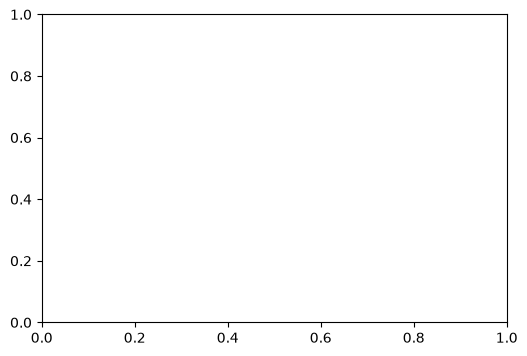

In [57]:
V_t = 0.35   # tube volume (L) 
V_b = 3.5      # beaker volume (L)
kA = 0.05      # mass transfer coefficient (L/hr)
Q = 0       # flow rate (L/hr) for continuous case
change_time = 3

t_end = 48     # total time (hours)
model = f"""
tube_c -> beaker_c; {kA}*(tube_c/{V_t} - beaker_c/{V_b}) 
beaker_c ->; rate * beaker_c/{V_b}
tube_c = 100
rate = {Q}
"""
rr = te.loada(model)
plot_3 =rr.simulate(0,48,1000, selections=['tube_c'])
rr.plot()
# rr = te.loada(model)
# plot2 = rr.simulate(0,50,1000, selections=['tube_c'])

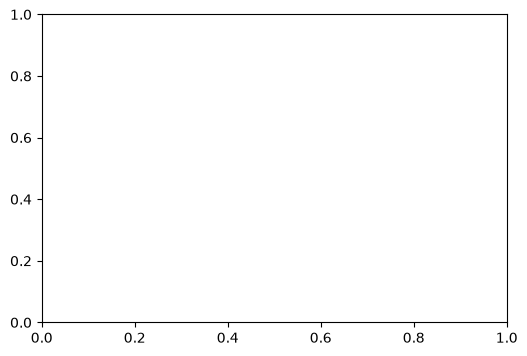

In [63]:
# V_t = 0.5   # tube volume (L) 
# V_b = 0.5      # beaker volume (L)
# kA = 0.05      # mass transfer coefficient (L/hr)
Q = 0.2        # flow rate (L/hr) for continuous case
change_time = 3

t_end = 48     # total time (hours)
model = f"""
tube_c -> beaker_c; {kA}*(tube_c/{V_t} - beaker_c/{V_b})
beaker_c ->; rate * beaker_c/{V_b}
tube_c = 100
rate = {Q}
"""
rr = te.loada(model)
plot1 = rr.simulate(0,48,1000,selections=['tube_c'])
rr.plot()
# rr = te.loada(model)
# plot2 = rr.simulate(0,50,1000, selections=['tube_c'])

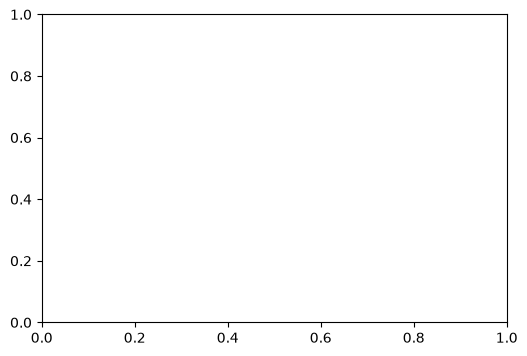

In [59]:
# V_t = 0.5   # tube volume (L) 
# V_b = 0.5      # beaker volume (L)
# kA = 0.05      # mass transfer coefficient (L/hr)
Q = 0        # flow rate (L/hr) for continuous case
change_time = 3

t_end = 48     # total time (hours)
model = f"""
tube_c -> beaker_c; {kA}*(tube_c/{V_t} - beaker_c/{V_b})
beaker_c ->; rate * beaker_c/{V_b}
tube_c = 100
rate = {Q}
next_reset = {change_time}
at (time >= next_reset): 
    beaker_c = 0, next_reset = next_reset + {change_time}
"""
rr = te.loada(model)
plot2 = rr.simulate(0,48,1000,selections=['tube_c'])
rr.plot()
# rr = te.loada(model)
# plot2 = rr.simulate(0,50,1000, selections=['tube_c'])

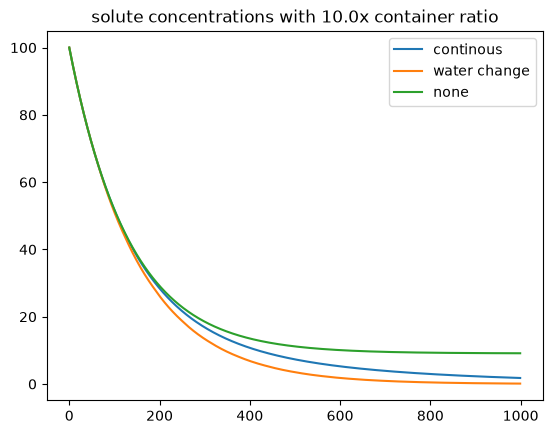

In [64]:
plt.plot(np.arange(0,len(plot1)),plot1,label='continous')
plt.plot(np.arange(0,len(plot2)),plot2,label='water change')
plt.plot(np.arange(0,len(plot_3)),plot_3,label='none')
plt.legend()
plt.title(f"solute concentrations with {V_b/V_t}x container ratio")
plt.show()